# Локальные эксперименты на CPU

ZIP конкурса нужен в `data/petfinder-adoption-prediction.zip` (после клонирования: `git lfs pull`).

Сначала загружаются CSV и выполняется EDA.
По умолчанию `RUN_HW1=False`: повторное обучение моделей ДЗ1 пропускается.
Чтобы его включить, `RUN_HW1=True`, набор моделей выбирается через `CONFIG_PATH`.

Для ДЗ2 JSON первого фото читаются прямо из ZIP. `INCLUDE_MEDIA=True` для этого не требуется.

In [5]:
import sys
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

candidates = [Path.cwd() / 'adoption_prediction', Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p.resolve() for p in candidates if (p / 'src/train.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Откройте notebook внутри репозитория adoption_prediction')
sys.path.insert(0, str(PROJECT_ROOT))

import json
import pandas as pd
import yaml
from IPython.display import display, Image
from src.prepare_data import default_data_source, resolve_data_root
from src.data import load_data
from src.eda import run_eda
from src.train import environment, run_cv, fit_submission
from src.report import build_report
from src.evaluate import group_bootstrap, save_json

print('Project:', PROJECT_ROOT)
display(environment())

Project: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction


{'python': '3.9.6',
 'packages': {'numpy': '1.26.4',
  'pandas': '2.2.3',
  'scikit-learn': '1.5.2',
  'scipy': '1.13.1',
  'catboost': '1.2.8',
  'matplotlib': '3.9.4',
  'PyYAML': '6.0.2',
  'joblib': '1.4.2'}}

In [6]:
DATA_SOURCE = default_data_source()  # Можно заменить на путь к ZIP или папке CSV.
INCLUDE_MEDIA = False  # True — распаковать также все JPG и JSON.
# CONFIG_PATH = PROJECT_ROOT / 'configs/baseline.yaml'
CONFIG_PATH = PROJECT_ROOT / 'configs/experiments.yaml'
RUN_HW1 = False  # Включить, если нужно повторить обучение ДЗ1.
RUN_REFIT = False
RUN_DIR = PROJECT_ROOT / 'outputs' / datetime.now(ZoneInfo('Europe/Moscow')).strftime('local_%Y%m%d_%H%M%S')

CONFIG = yaml.safe_load(CONFIG_PATH.read_text())
DATA_ROOT = resolve_data_root(DATA_SOURCE, include_media=INCLUDE_MEDIA)
train, test = load_data(DATA_ROOT)
print('Data:', DATA_ROOT)
print('Output:', RUN_DIR)
print('Train:', train.shape, 'test:', test.shape)
display(CONFIG)

Data: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/data/raw/petfinder-adoption-prediction/2083562071-1794647197613683780
Output: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/outputs/local_20261116_144430
Train: (14993, 24) test: (3972, 23)


{'seed': 42,
 'split': 'stratified_group',
 'n_splits': 5,
 'models': ['dummy',
  'logreg_tabular',
  'logreg_text',
  'catboost_regressor',
  'catboost_classifier'],
 'bootstrap_repeats': 500,
 'logreg': {'C': 1.0, 'max_iter': 1500},
 'text': {'max_features': 20000},
 'catboost': {'iterations': 400,
  'depth': 6,
  'learning_rate': 0.05,
  'l2_leaf_reg': 3,
  'thread_count': 2}}

## EDA

При `INCLUDE_MEDIA=False` наличие самих изображений и JSON не проверяется, если они еще не распакованы.

{'train': {'shape': [14993, 24],
  'missing_columns': [],
  'null_counts': {'Type': 0,
   'Name': 1265,
   'Age': 0,
   'Breed1': 0,
   'Breed2': 0,
   'Gender': 0,
   'Color1': 0,
   'Color2': 0,
   'Color3': 0,
   'MaturitySize': 0,
   'FurLength': 0,
   'Vaccinated': 0,
   'Dewormed': 0,
   'Sterilized': 0,
   'Health': 0,
   'Quantity': 0,
   'Fee': 0,
   'State': 0,
   'RescuerID': 0,
   'VideoAmt': 0,
   'Description': 13,
   'PetID': 0,
   'PhotoAmt': 0,
   'AdoptionSpeed': 0},
  'empty_string_counts': {'Name': 1265, 'Description': 13},
  'duplicate_rows': 0,
  'duplicate_pet_ids': 0,
  'repeated_nonempty_descriptions': 973,
  'nonempty_descriptions_with_non_ascii': 597,
  'invalid_code_counts': {'Type': 0,
   'Gender': 0,
   'MaturitySize': 0,
   'FurLength': 0,
   'Health': 0,
   'Vaccinated': 0,
   'Dewormed': 0,
   'Sterilized': 0},
  'negative_numeric_counts': {'Age': 0,
   'Quantity': 0,
   'Fee': 0,
   'VideoAmt': 0,
   'PhotoAmt': 0},
  'non_numeric_counts': {'Age': 0,
 

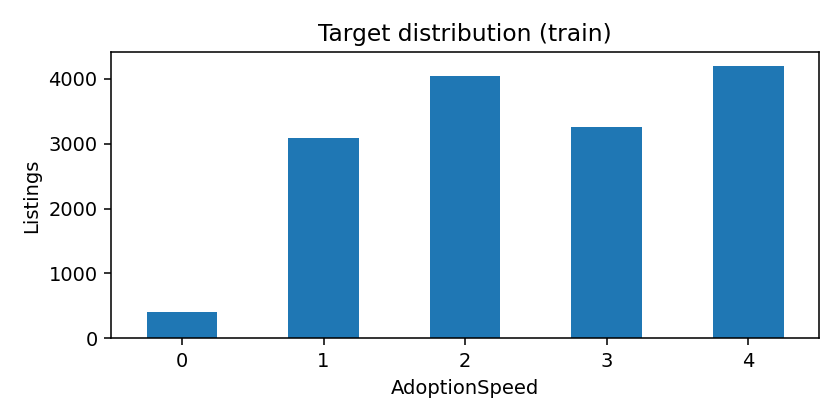

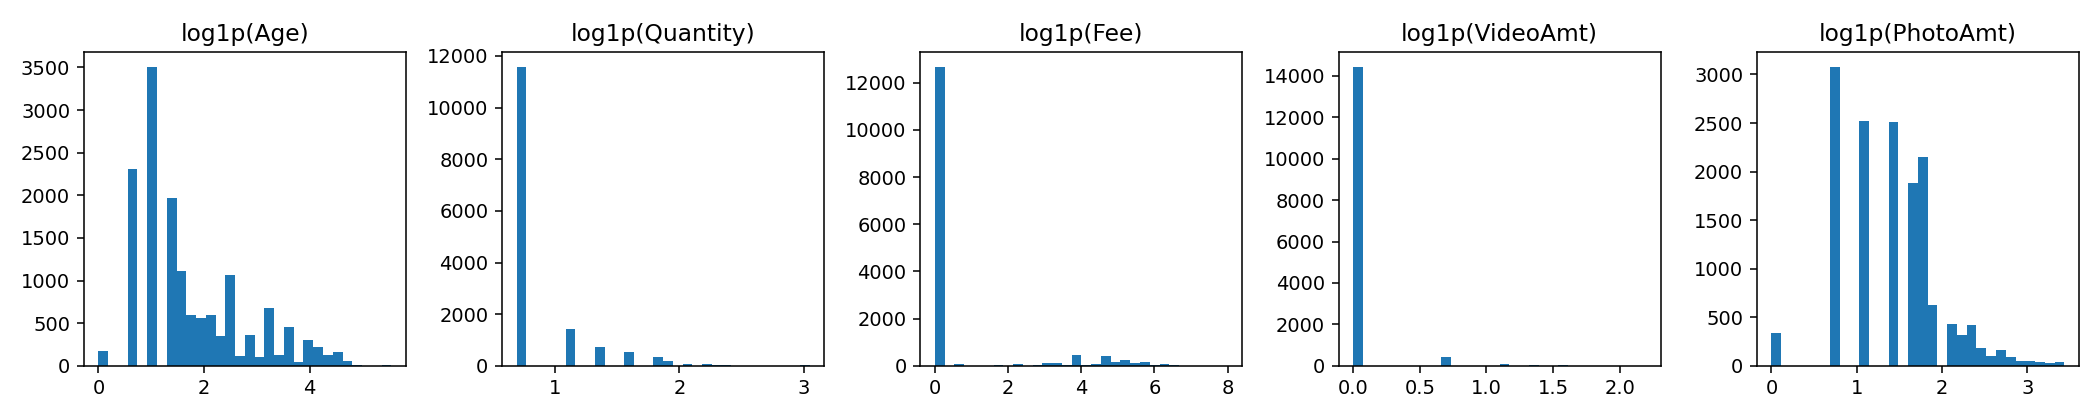

In [7]:
audit = run_eda(train, test, RUN_DIR / 'eda', DATA_ROOT)
display(audit)
display(Image(filename=str(RUN_DIR / 'eda/class_distribution.png')))
display(Image(filename=str(RUN_DIR / 'eda/numeric_distributions.png')))

In [8]:
if RUN_HW1:
    summary = run_cv(train, CONFIG, RUN_DIR / 'experiments')
    display(summary)
    report_path = build_report(RUN_DIR / 'experiments')
    print('Report:', report_path)
    display(Image(filename=str(RUN_DIR / 'experiments/model_comparison.png')))
    best_model = summary.iloc[0]['model']
    display(Image(filename=str(RUN_DIR / 'experiments' / best_model / 'confusion_matrix.png')))
    display(pd.read_csv(RUN_DIR / 'experiments' / best_model / 'errors.csv').head(3))
else:
    print('Обучение ДЗ1 пропущено, ниже запускается ДЗ2.')

Обучение ДЗ1 пропущено, ниже запускается ДЗ2.


## Гипотеза о тексте

Этот блок выполняется, если в конфиге есть обе Logistic Regression (tabular и text).

Интервал пересэмплирует авторов и относится к уже полученным OOF, без переобучения моделей.

In [9]:
if RUN_HW1 and {'logreg_tabular', 'logreg_text'}.issubset(set(summary.model)):
    results = RUN_DIR / 'experiments'
    text_oof = pd.read_csv(results / 'logreg_text/oof.csv')
    tab_oof = pd.read_csv(results / 'logreg_tabular/oof.csv')
    paired = text_oof.merge(tab_oof[['PetID', 'fold', 'y_true', 'prediction']],
                            on=['PetID', 'fold', 'y_true'], suffixes=('', '_tab'), validate='one_to_one')
    assert len(paired) == len(train)
    by_model = summary.set_index('model')
    result = {
        'delta_oof_qwk_text_minus_tabular': float(by_model.loc['logreg_text', 'oof_qwk'] - by_model.loc['logreg_tabular', 'oof_qwk']),
        'paired_group_bootstrap': group_bootstrap(paired, repeats=CONFIG.get('bootstrap_repeats', 500),
                                                  seed=CONFIG['seed'], other='prediction_tab'),
    }
    save_json(result, results / 'text_hypothesis.json')
    display(result)

## Refit и submission (по желанию)

Если RUN_REFIT=True, победитель локальной CV обучается на всем train и предсказывает test.

In [10]:
if RUN_HW1 and RUN_REFIT:
    sample_candidates = [DATA_ROOT / 'sample_submission.csv', DATA_ROOT / 'test/sample_submission.csv']
    sample_path = next((p for p in sample_candidates if p.is_file()), None)
    submission = fit_submission(train, test, CONFIG, best_model, RUN_DIR / 'refit', sample_path)
    display(submission.head())
    print('Submission:', RUN_DIR / 'refit/submission.csv')

## ДЗ2: веса классов и метаданные первого фото

Точка отсчета — CatBoostClassifier из ДЗ1. Проверяю два изменения при тех же параметрах деревьев:

- **Веса классов:** `SqrtBalanced` (более мягкое взвешивание в сравнении с balanced, не хочется повышать количество ложных нулей) повысит recall класса 0 хотя бы до 5% при снижении mean QWK не больше 0.01 относительно исходного CatBoost. Рост recall отдельно не означает улучшения QWK, смотрим также precision класса 0.
- **Метаданные первого фото:** признаки из Vision JSON дадут не менее +0.01 mean QWK относительно исходного CatBoost. Они могут дополнить `PhotoAmt`, который описывает только количество фотографий.

Четыре варианта: исходный CatBoost, только веса, только метаданные, оба изменения.
Две абляции — убираю из полной версии веса или метаданные.
Лучшую модель выбираю по mean fold QWK.

In [ ]:
from copy import deepcopy
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, precision_score
from src.data import TARGET, CLASSES, file_sha256
from src.photo_features import PHOTO_FEATURES, load_photo_features
from src.train import make_folds

HW2_CONFIG = yaml.safe_load((PROJECT_ROOT / 'configs/hw2.yaml').read_text())
HW2_DIR = PROJECT_ROOT / 'outputs' / datetime.now(ZoneInfo('Europe/Moscow')).strftime('hw2_%Y%m%d_%H%M%S_%f')
HW2_DIR.mkdir(parents=True, exist_ok=False)
RUN_HW2_REFIT = False

FOLDS_SOURCE = PROJECT_ROOT / 'reports/2026-11-08_group_cv_seed42/experiments/folds.csv'
fixed_folds, fold_diagnostics = make_folds(train, HW2_CONFIG, folds=FOLDS_SOURCE)
folds_hw2 = train[['PetID', 'RescuerID', TARGET]].assign(fold=fixed_folds)
FOLDS_PATH = HW2_DIR / 'folds.csv'
folds_hw2.to_csv(FOLDS_PATH, index=False)
save_json(fold_diagnostics, HW2_DIR / 'split_diagnostics.json')
save_json({'environment': environment(), 'folds_source': str(FOLDS_SOURCE),
           'folds_sha256': file_sha256(FOLDS_SOURCE), 'data_source': str(DATA_SOURCE)},
          HW2_DIR / 'input.json')

EXPERIMENTS = [
    {'name': 'baseline', 'weights': None, 'photo_metadata': False,
     'hypothesis': 'Исходный CatBoostClassifier из ДЗ1'},
    {'name': 'weights', 'weights': 'SqrtBalanced', 'photo_metadata': False,
     'hypothesis': 'Recall класса 0 >= 0.05, delta mean QWK >= -0.01 к baseline'},
    {'name': 'metadata', 'weights': None, 'photo_metadata': True,
     'hypothesis': 'Delta mean QWK >= 0.01 к baseline'},
    {'name': 'full', 'weights': 'SqrtBalanced', 'photo_metadata': True,
     'hypothesis': 'Проверка совместного эффекта двух изменений'},
]
EXPERIMENT_CONFIGS = {}
for spec in EXPERIMENTS:
    config = deepcopy(HW2_CONFIG)
    config['features']['photo_metadata'] = spec['photo_metadata']
    if spec['weights'] is not None:
        config['catboost']['auto_class_weights'] = spec['weights']
    EXPERIMENT_CONFIGS[spec['name']] = config
save_json({'experiments': EXPERIMENTS,
           'weights_criterion': {'recall_class_0_min': 0.05, 'delta_mean_qwk_min': -0.01},
           'metadata_criterion': {'delta_mean_qwk_min': 0.01}}, HW2_DIR / 'plan.json')
print('Output:', HW2_DIR)
display(pd.DataFrame(EXPERIMENTS))
display(pd.DataFrame(fold_diagnostics))

Output: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/outputs/hw2_20261116_144455_839213


,name,weights,photo_metadata,hypothesis
0,baseline,None,False,Исходный CatBoostClassifier из ДЗ1
1,weights,SqrtBalanced,False,"Recall класса 0 >= 0.05, delta mean QWK >= -0...."
2,metadata,None,True,Delta mean QWK >= 0.01 к baseline
3,full,SqrtBalanced,True,Проверка совместного эффекта двух изменений


,fold,train_rows,val_rows,overlapping_rescuers,val_rows_with_train_description,train_class_counts,val_class_counts
0,0,11804,3189,0,24,"{0: 319, 1: 2478, 2: 3181, 3: 2512, 4: 3314}","{0: 91, 1: 612, 2: 856, 3: 747, 4: 883}"
1,1,11618,3375,0,44,"{0: 309, 1: 2443, 2: 3101, 3: 2443, 4: 3322}","{0: 101, 1: 647, 2: 936, 3: 816, 4: 875}"
2,2,12204,2789,0,30,"{0: 332, 1: 2478, 2: 3319, 3: 2710, 4: 3365}","{0: 78, 1: 612, 2: 718, 3: 549, 4: 832}"
3,3,12384,2609,0,38,"{0: 338, 1: 2512, 2: 3413, 3: 2754, 4: 3367}","{0: 72, 1: 578, 2: 624, 3: 505, 4: 830}"
4,4,11962,3031,0,198,"{0: 342, 1: 2449, 2: 3134, 3: 2617, 4: 3420}","{0: 68, 1: 641, 2: 903, 3: 642, 4: 777}"


### Признаки из Vision JSON

Использую только `<PetID>-1.json`: число меток, максимальный confidence, confidence меток `cat`/`dog` и средние RGB доминирующих цветов с весами `pixelFraction`.
Отсутствие файла, меток и цветов отмечается отдельными флагами, недоступные числовые значения остаются NaN.
Если список меток есть, но `cat` или `dog` в нем нет, score равен нулю.

Признаки рассчитываются отдельно для каждого объявления без target и общих статистик.
Веса классов рассчитывает CatBoost только по train-части каждого фолда.
При работе с распакованными данными нужны папки `train_metadata`/`test_metadata` в корне данных.

In [12]:
PHOTO_SOURCE = DATA_SOURCE if Path(DATA_SOURCE).is_file() else DATA_ROOT
photo_train = load_photo_features(PHOTO_SOURCE, train.PetID, split='train')
feature_dir = HW2_DIR / 'photo_features'
feature_dir.mkdir(exist_ok=True)
photo_train.to_csv(feature_dir / 'train.csv', index=False)
train_hw2 = train.join(photo_train.set_index('PetID'), on='PetID', validate='one_to_one')
photo_audit = {
    'source': str(PHOTO_SOURCE), 'rows': len(photo_train), 'photo_number': 1,
    'features': PHOTO_FEATURES,
    'missing_metadata': int(photo_train.photo_metadata_missing.sum()),
    'missing_labels': int(photo_train.photo_labels_missing.sum()),
    'missing_colors': int(photo_train.photo_colors_missing.sum()),
    'rows_without_metadata_but_with_photos': int(
        ((train_hw2.photo_metadata_missing == 1) & (train_hw2.PhotoAmt > 0)).sum()),
}
save_json(photo_audit, feature_dir / 'audit.json')
display(photo_audit)
display(photo_train[PHOTO_FEATURES].agg(['count', 'mean', 'min', 'max']).T)

train: JSON первого фото найден для 14652 из 14993 объявлений


{'source': '/Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/data/petfinder-adoption-prediction.zip',
 'rows': 14993,
 'photo_number': 1,
 'features': ['photo_metadata_missing',
  'photo_labels_missing',
  'photo_colors_missing',
  'photo_label_count',
  'photo_max_label_score',
  'photo_cat_score',
  'photo_dog_score',
  'photo_red',
  'photo_green',
  'photo_blue'],
 'missing_metadata': 341,
 'missing_labels': 343,
 'missing_colors': 341,
 'rows_without_metadata_but_with_photos': 0}

,count,mean,min,max
photo_metadata_missing,14993.0,0.022744,0.000000,1.000000
photo_labels_missing,14993.0,0.022877,0.000000,1.000000
photo_colors_missing,14993.0,0.022744,0.000000,1.000000
photo_label_count,14650.0,9.432628,1.000000,10.000000
photo_max_label_score,14650.0,0.971844,0.517198,0.995285
photo_cat_score,14650.0,0.442015,0.000000,0.995285
photo_dog_score,14650.0,0.510904,0.000000,0.992593
photo_red,14652.0,127.390570,17.695248,249.411109
photo_green,14652.0,116.609033,14.959893,244.554992
photo_blue,14652.0,105.920794,7.100156,242.917455


### Четыре эксперимента

На каждый вариант приходится пять обучений CatBoost. Параметры деревьев и фолды одинаковы.
Варианты без метаданных игнорируют все новые столбцы.
Для каждого запуска сохраняются конфиг, окружение и кодовые хеши, OOF, метрики, ошибки и графики.
`experiments.csv` обновляется после каждого готового варианта, а `status.json` показывает, завершилось ли обучение.

Эту ячейку можно выполнять без повторного запуска блоков ДЗ1. Повторное выполнение перезапишет результаты четырёх вариантов в текущем `HW2_DIR`.

In [13]:
run_rows = []
for spec in EXPERIMENTS:
    name = spec['name']
    destination = HW2_DIR / name
    destination.mkdir(exist_ok=True)
    config = EXPERIMENT_CONFIGS[name]
    save_json({**spec, 'status': 'running'}, destination / 'status.json')
    print(f"\n{name}: weights={spec['weights']}, metadata={spec['photo_metadata']}", flush=True)
    started = time.perf_counter()
    try:
        result = run_cv(train_hw2, config, destination, folds=FOLDS_PATH)
        build_report(destination)
        oof = pd.read_csv(destination / 'catboost_classifier/oof.csv')
        row = result.iloc[0].to_dict()
        row.update(experiment=name, hypothesis=spec['hypothesis'],
                   weights=spec['weights'] or 'None', photo_metadata=spec['photo_metadata'],
                   seed=config['seed'], n_splits=config['n_splits'],
                   oof_precision_class_0=float(precision_score(
                       oof.y_true, oof.prediction, labels=[0], average=None, zero_division=0)[0]),
                   total_seconds=time.perf_counter() - started)
        run_rows.append(row)
        pd.DataFrame(run_rows).to_csv(HW2_DIR / 'experiments.csv', index=False)
        save_json({**spec, 'status': 'complete'}, destination / 'status.json')
    except Exception as error:
        save_json({**spec, 'status': 'failed', 'error': str(error)}, destination / 'status.json')
        raise
hw2_summary = pd.DataFrame(run_rows)
baseline_qwk = float(hw2_summary.set_index('experiment').loc['baseline', 'qwk_mean'])
hw2_summary['delta_mean_qwk'] = hw2_summary.qwk_mean - baseline_qwk
hw2_summary.to_csv(HW2_DIR / 'experiments.csv', index=False)
display(hw2_summary[['experiment', 'qwk_mean', 'qwk_std', 'delta_mean_qwk', 'oof_macro_f1',
                     'oof_recall_class_0', 'oof_precision_class_0', 'oof_severe_error_rate', 'seconds']])


baseline: weights=None, metadata=False
catboost_classifier fold=0 QWK=0.34094313624764727
catboost_classifier fold=1 QWK=0.33357971686517207
catboost_classifier fold=2 QWK=0.3432728360943791
catboost_classifier fold=3 QWK=0.3380204784425833
catboost_classifier fold=4 QWK=0.2937455133284267

weights: weights=SqrtBalanced, metadata=False
catboost_classifier fold=0 QWK=0.34190335386786663
catboost_classifier fold=1 QWK=0.33284584326191047
catboost_classifier fold=2 QWK=0.33715012258618027
catboost_classifier fold=3 QWK=0.3386331718677359
catboost_classifier fold=4 QWK=0.29966481093950414

metadata: weights=None, metadata=True
catboost_classifier fold=0 QWK=0.3326619845939962
catboost_classifier fold=1 QWK=0.3526765958642929
catboost_classifier fold=2 QWK=0.35931893180330254
catboost_classifier fold=3 QWK=0.3427079341969743
catboost_classifier fold=4 QWK=0.30355218619002144

full: weights=SqrtBalanced, metadata=True
catboost_classifier fold=0 QWK=0.3383610782772697
catboost_classifier fol

,experiment,qwk_mean,qwk_std,delta_mean_qwk,oof_macro_f1,oof_recall_class_0,oof_precision_class_0,oof_severe_error_rate,seconds
0,baseline,0.329912,0.020539,0.000000,0.286963,0.000000,0.000000,0.268459,581.815682
1,weights,0.330039,0.017289,0.000127,0.296155,0.014634,0.088235,0.276396,622.678807
2,metadata,0.338184,0.021835,0.008271,0.289036,0.000000,0.000000,0.262122,714.897199
3,full,0.336453,0.011968,0.006541,0.298584,0.017073,0.094595,0.272594,439.860423


### Сравнения и две абляции

Сравниваем каждый вариант с исходным CatBoost. Для абляций сравниваем `full` с `metadata` (убрали веса) и с `weights` (убрали метаданные).
Положительная разница `full − вариант без компонента` означает пользу компонента в полной версии.

Mean QWK относится к фолдам. Bootstrap-интервалы ниже — для разницы pooled OOF QWK, с пересэмплированием целых авторов и без переобучения моделей.
Они описывают эти OOF-предсказания и не учитывают всю неопределённость выбора лучшего из нескольких вариантов.

In [14]:
hw2_summary = pd.read_csv(HW2_DIR / 'experiments.csv')
by_experiment = hw2_summary.set_index('experiment')
oof_by_experiment = {
    name: pd.read_csv(HW2_DIR / name / 'catboost_classifier/oof.csv')
    for name in by_experiment.index
}
comparisons = []
pairs = [('weights', 'baseline'), ('metadata', 'baseline'), ('full', 'baseline'),
         ('full', 'metadata'), ('full', 'weights')]
keys = ['PetID', 'RescuerID', 'fold', 'y_true']
for candidate, reference in pairs:
    paired = oof_by_experiment[candidate].merge(
        oof_by_experiment[reference][keys + ['prediction']], on=keys,
        suffixes=('', '_reference'), validate='one_to_one')
    if len(paired) != len(train):
        raise ValueError(f'OOF не совпали: {candidate}, {reference}')
    interval = group_bootstrap(paired, repeats=HW2_CONFIG['bootstrap_repeats'],
                               seed=HW2_CONFIG['seed'], other='prediction_reference')
    comparisons.append({
        'candidate': candidate, 'reference': reference,
        'delta_mean_qwk': by_experiment.loc[candidate, 'qwk_mean'] - by_experiment.loc[reference, 'qwk_mean'],
        'delta_oof_qwk': by_experiment.loc[candidate, 'oof_qwk'] - by_experiment.loc[reference, 'oof_qwk'],
        'bootstrap_low': interval['low'], 'bootstrap_high': interval['high'],
        'valid_repeats': interval['valid_repeats'],
        'delta_recall_class_0': by_experiment.loc[candidate, 'oof_recall_class_0'] - by_experiment.loc[reference, 'oof_recall_class_0'],
    })
comparisons = pd.DataFrame(comparisons)
comparisons.to_csv(HW2_DIR / 'comparisons.csv', index=False)
hypothesis_checks = {
    'weights_criterion_met': bool(by_experiment.loc['weights', 'oof_recall_class_0'] >= 0.05
                                 and by_experiment.loc['weights', 'delta_mean_qwk'] >= -0.01),
    'metadata_criterion_met': bool(by_experiment.loc['metadata', 'delta_mean_qwk'] >= 0.01),
    'best_experiment_by_mean_qwk': str(hw2_summary.sort_values('qwk_mean', ascending=False).iloc[0].experiment),
}
save_json(hypothesis_checks, HW2_DIR / 'hypothesis_checks.json')
display(comparisons)
display(hypothesis_checks)

class_rows = []
for name, oof in oof_by_experiment.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        oof.y_true, oof.prediction, labels=CLASSES, zero_division=0)
    class_rows.extend({'experiment': name, 'class': label, 'precision': float(precision[i]),
                       'recall': float(recall[i]), 'f1': float(f1[i]), 'support': int(support[i])}
                      for i, label in enumerate(CLASSES))
class_metrics = pd.DataFrame(class_rows)
class_metrics.to_csv(HW2_DIR / 'class_metrics.csv', index=False)
display(class_metrics.pivot(index='class', columns='experiment', values='recall'))

,candidate,reference,delta_mean_qwk,delta_oof_qwk,bootstrap_low,bootstrap_high,valid_repeats,delta_recall_class_0
0,weights,baseline,0.000127,0.000555,-0.006765,0.007862,500,0.014634
1,metadata,baseline,0.008271,0.008240,-0.000623,0.017720,500,0.000000
2,full,baseline,0.006541,0.006637,-0.003141,0.015732,500,0.017073
3,full,metadata,-0.001731,-0.001602,-0.010019,0.007764,500,0.017073
4,full,weights,0.006413,0.006082,-0.002168,0.014538,500,0.002439


{'weights_criterion_met': False,
 'metadata_criterion_met': False,
 'best_experiment_by_mean_qwk': 'metadata'}

experiment,baseline,full,metadata,weights
class,,,,
0,0.000000,0.017073,0.000000,0.014634
1,0.311650,0.401942,0.306472,0.407767
2,0.420114,0.317067,0.421105,0.316572
3,0.129488,0.173673,0.133477,0.167843
4,0.658327,0.641172,0.669288,0.635692


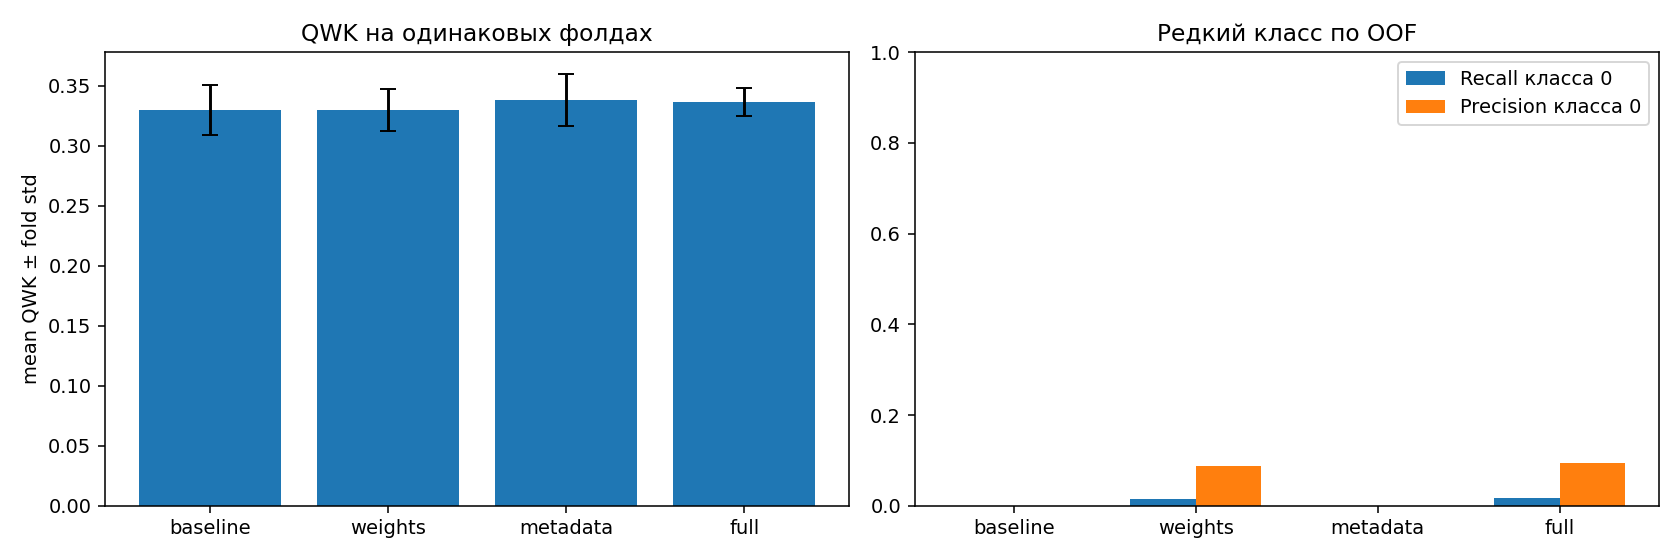

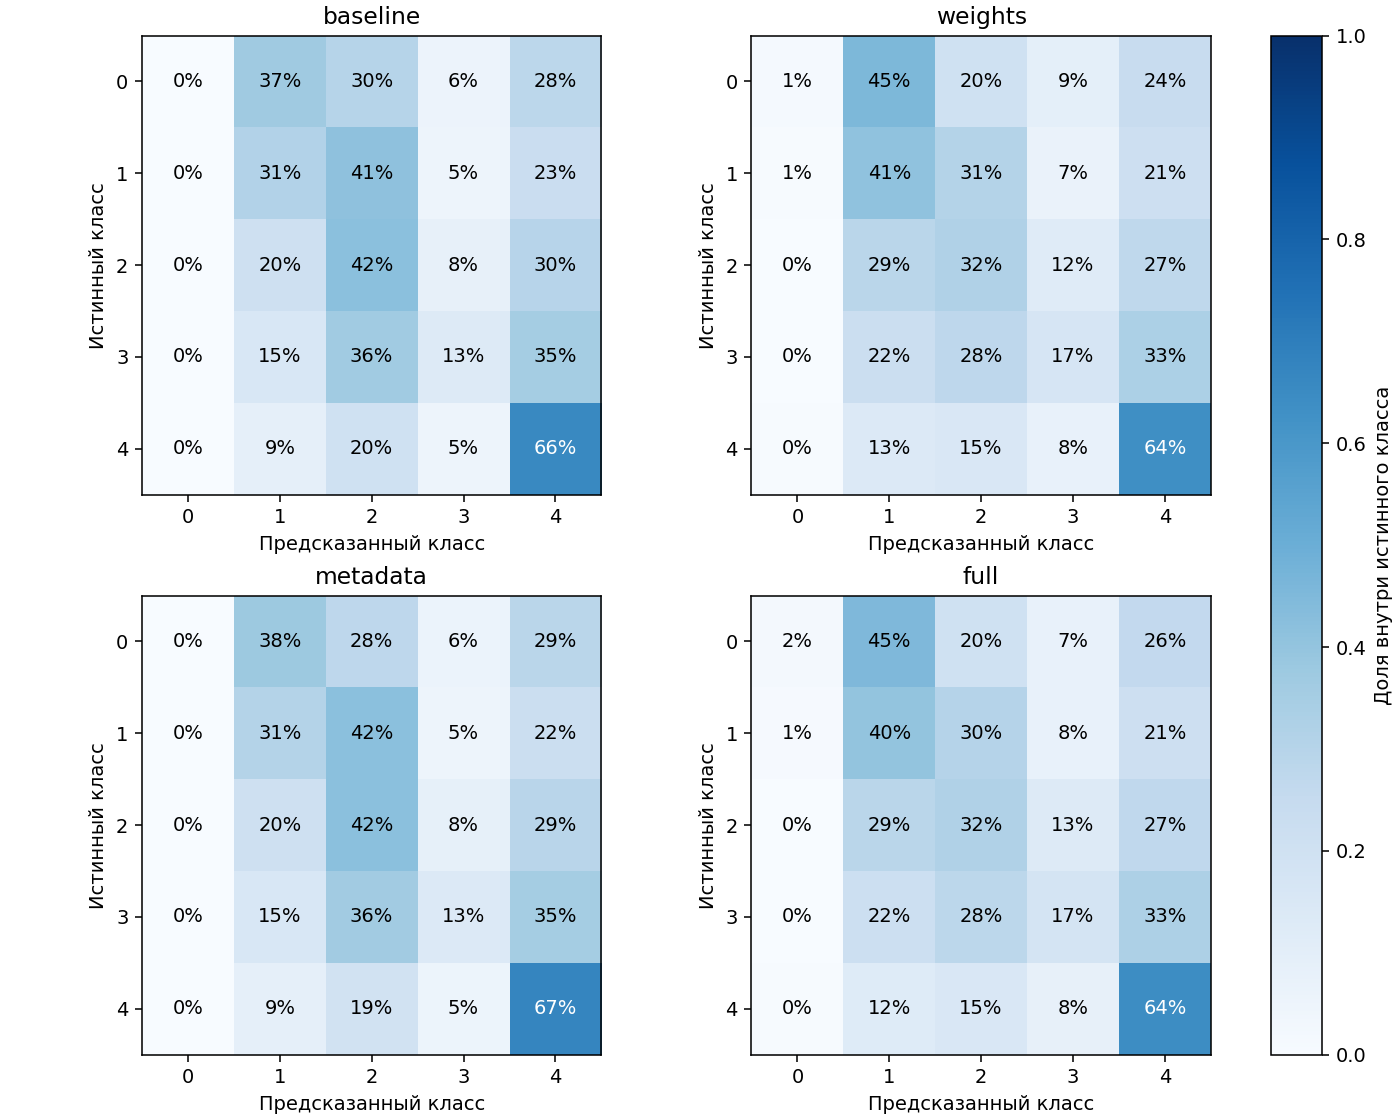

Все результаты ДЗ2: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/outputs/hw2_20261116_144455_839213


In [ ]:
names = [spec['name'] for spec in EXPERIMENTS]
chart = by_experiment.loc[names]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(names, chart.qwk_mean, yerr=chart.qwk_std, capsize=4)
axes[0].set(title='QWK на одинаковых фолдах', ylabel='mean QWK +- fold std')
positions = np.arange(len(names))
axes[1].bar(positions - 0.18, chart.oof_recall_class_0, width=0.36, label='Recall класса 0')
axes[1].bar(positions + 0.18, chart.oof_precision_class_0, width=0.36, label='Precision класса 0')
axes[1].set(xticks=positions, xticklabels=names, ylim=(0, 1), title='Редкий класс по OOF')
axes[1].legend()
fig.tight_layout()
fig.savefig(HW2_DIR / 'comparison.png', dpi=140)
plt.close(fig)
display(Image(filename=str(HW2_DIR / 'comparison.png')))

fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout='constrained')
for ax, name in zip(axes.flat, names):
    matrix = pd.read_csv(HW2_DIR / name / 'catboost_classifier/confusion_matrix.csv', index_col=0)
    normalized = matrix.div(matrix.sum(axis=1), axis=0).fillna(0).to_numpy()
    image = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
    for (i, j), value in np.ndenumerate(normalized):
        ax.text(j, i, f'{value:.0%}', ha='center', va='center',
                color='white' if value > 0.5 else 'black')
    ax.set(title=name, xlabel='Предсказанный класс', ylabel='Истинный класс',
           xticks=CLASSES, yticks=CLASSES)
fig.colorbar(image, ax=axes.ravel().tolist(), label='Доля внутри истинного класса')
fig.savefig(HW2_DIR / 'confusion_matrices.png', dpi=140)
plt.close(fig)
display(Image(filename=str(HW2_DIR / 'confusion_matrices.png')))
print('Все результаты ДЗ2:', HW2_DIR)

### Refit ДЗ2 по желанию

По умолчанию выключен. В целом нужен только для submission (`RUN_HW2_REFIT` = True).
Вариант выбирается только по mean QWK на CV.

In [ ]:
if RUN_HW2_REFIT:
    best_experiment = hypothesis_checks['best_experiment_by_mean_qwk']
    best_config = EXPERIMENT_CONFIGS[best_experiment]
    test_hw2 = test.copy()
    if best_config['features']['photo_metadata']:
        photo_test = load_photo_features(PHOTO_SOURCE, test.PetID, split='test')
        photo_test.to_csv(feature_dir / 'test.csv', index=False)
        test_hw2 = test.join(photo_test.set_index('PetID'), on='PetID', validate='one_to_one')
    sample_candidates = [DATA_ROOT / 'sample_submission.csv', DATA_ROOT / 'test/sample_submission.csv']
    sample_path = next((p for p in sample_candidates if p.is_file()), None)
    submission_hw2 = fit_submission(train_hw2, test_hw2, best_config, 'catboost_classifier',
                                    HW2_DIR / 'refit', sample_path)
    save_json({'experiment': best_experiment}, HW2_DIR / 'refit/experiment.json')
    display(submission_hw2.head())
    print('Submission:', HW2_DIR / 'refit/submission.csv')

## ДЗ3: анализ ошибок, устойчивость и ограничения

Этот раздел можно запускать с первой ячейки ниже после перезапуска ядра. Блоки ДЗ1 и ДЗ2 повторять не нужно.
Для анализа выбран CatBoost с метаданными первого фото без весов: mean QWK 0.3382 +- 0.0218, пять групповых фолдов по RescuerID, seed=42.
Конфигурация и OOF берутся из сохранённого эксперимента `reports/2026-11-16_hw2_group_cv_seed42/metadata`.

Сначала использую готовые OOF для ошибок и срезов. Затем проверяю другие разбиения и неточность возраста.

In [1]:
import sys
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

hw3_candidates = [Path.cwd() / 'adoption_prediction', Path.cwd(), *Path.cwd().parents]
HW3_ROOT = next((p.resolve() for p in hw3_candidates if (p / 'src/train.py').is_file()), None)
if HW3_ROOT is None:
    raise FileNotFoundError('Откройте notebook внутри репозитория adoption_prediction')
if str(HW3_ROOT) not in sys.path:
    sys.path.insert(0, str(HW3_ROOT))

from copy import deepcopy
import numpy as np
import pandas as pd
import yaml
from IPython.display import display, Image, Markdown
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from src.data import CLASSES, TARGET, load_data, file_sha256
from src.prepare_data import default_data_source, resolve_data_root
from src.photo_features import PHOTO_FEATURES, load_photo_features
from src.train import environment, make_folds, run_cv
from src.evaluate import metrics, save_json
from src.diagnostics import (join_oof, slice_metrics, error_examples, export_first_photos,
                             class_metrics as diagnostic_class_metrics, run_age_noise)

HW3_SETTINGS = yaml.safe_load((HW3_ROOT / 'configs/hw3.yaml').read_text())
HW3_REFERENCE = HW3_ROOT / HW3_SETTINGS['reference_run']
HW3_MODEL_CONFIG = yaml.safe_load((HW3_REFERENCE / 'config.yaml').read_text())
HW3_DATA_SOURCE = default_data_source()  # Можно указать ZIP или папку данных вручную.
RUN_SPLIT_CHECK = True
RUN_AGE_NOISE_CHECK = True
HW3_DIR = HW3_ROOT / 'outputs' / datetime.now(ZoneInfo('Europe/Moscow')).strftime('hw3_%Y%m%d_%H%M%S_%f')
HW3_DIR.mkdir(parents=True, exist_ok=False)

hw3_data_root = resolve_data_root(HW3_DATA_SOURCE)
hw3_train, _ = load_data(hw3_data_root, with_test=False)
hw3_saved_oof = pd.read_csv(HW3_REFERENCE / 'catboost_classifier/oof.csv')
hw3_analysis = join_oof(hw3_train, hw3_saved_oof)
hw3_reference_folds = HW3_REFERENCE / 'folds.csv'
hw3_fold_ids, hw3_fold_diagnostics = make_folds(hw3_train, HW3_MODEL_CONFIG, folds=hw3_reference_folds)
if not np.array_equal(hw3_fold_ids, hw3_analysis.fold.to_numpy()):
    raise ValueError('Фолды OOF отличаются от выбранного эксперимента ДЗ2')
hw3_reference_summary = pd.read_csv(HW3_REFERENCE / 'summary.csv').iloc[0]
(HW3_DIR / 'model_config.yaml').write_text(yaml.safe_dump(HW3_MODEL_CONFIG, allow_unicode=True))
(HW3_DIR / 'checks_config.yaml').write_text(yaml.safe_dump(HW3_SETTINGS, allow_unicode=True))
save_json({'reference_run': str(HW3_REFERENCE), 'data_source': str(HW3_DATA_SOURCE),
           'reference_oof_sha256': file_sha256(HW3_REFERENCE / 'catboost_classifier/oof.csv'),
           'environment': environment(), 'run_split_check': RUN_SPLIT_CHECK,
           'run_age_noise_check': RUN_AGE_NOISE_CHECK}, HW3_DIR / 'input.json')
print('Output:', HW3_DIR)
print('Train:', hw3_train.shape, 'Model seed:', HW3_MODEL_CONFIG['seed'])
display(HW3_MODEL_CONFIG)
display(pd.DataFrame([metrics(hw3_analysis.y_true, hw3_analysis.prediction)]))

Output: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/outputs/hw3_20261126_135325_244431
Train: (14993, 24) Model seed: 42


{'bootstrap_repeats': 500,
 'catboost': {'depth': 6,
  'iterations': 400,
  'l2_leaf_reg': 3,
  'learning_rate': 0.05,
  'thread_count': 2},
 'features': {'photo_metadata': True},
 'models': ['catboost_classifier'],
 'n_splits': 5,
 'seed': 42,
 'split': 'stratified_group'}

,qwk,macro_f1,accuracy,mae,recall_class_0,severe_error_rate
0,0.338022,0.289036,0.392917,0.95738,0.0,0.262122


### Типовые ошибки и реальные карточки

Рассматриваем четыре паттерна: нераспознанный класс 0, соседние интервалы для класса 3, слишком оптимистичный и слишком пессимистичный прогнозы.
Частоты считаются по всем OOF, не по отдельным картинкам.

Для каждого паттерна выбирается самая частая пара `y -> prediction`, затем пример с возрастом, ближайшим к медианному внутри этой пары, ничьи решаются по PetID.
Правило не использует субъективную привлекательность фото. Описание и JPG извлекаются из исходных данных для осмотра.

,pattern,description,n_errors,n_target_class,share_in_target_class
0,same_day,Не распознан класс 0,410,410,1.000000
1,adjacent,Соседний интервал для класса 3,2326,3259,0.713716
2,optimistic,Слишком оптимистичный прогноз,1162,4197,0.276864
3,pessimistic,Слишком пессимистичный прогноз,844,3090,0.273139


,pattern,PetID,fold,y_true,prediction,Age,Quantity,Fee,PhotoAmt
0,same_day,015da9e87,0,0,1,2,1,0,5.0
1,adjacent,000fb9572,2,3,2,2,1,0,6.0
2,optimistic,01186c9fc,2,4,2,2,2,40,3.0
3,pessimistic,01e78230b,2,1,4,6,1,0,2.0


**Не распознан класс 0: 015da9e87, y=0, prediction=1**

Nama: Gebuk (Betina)- Adik beradik dengan Gebu (Jantan) Breed: DSH x DMH Ubat Cacing: diberikan 2 kali Warna: Seperti gambar Jantina: Betina Makan: IAM'S Kitten & Blackwood Kitten Nota: Diselamat dan diambil daripada seorang makcik yang tidak dapat menjaga kucing-kucing dia dengan baik. Dia cuba buang kucing ini di beberapa tempat dan telah buang beberapa kucing lain di berapa tempat tempat lain. Saya minta kucing ini untuk foster dan bantu dapatkan adopter dan mereka yang berminat untuk membela mereka. Saya ambil 4 ekor kucing daripada makcik tersebut yang mana masa tersebut amat kelaparan dan tidak lagi makan untuk hari berkenaan. Bau kucing2 itu amat hancing dan busuk dan ambil masa untuk mandikan kucing berkenaan. Setelah 2-3 kali mandi, alhamdullilah mereka telah bersih dan harum amat. Beberapa vitamin dan makanan berzat seperti Blackwood Kitten dan IAMS Kitten diberikan kepada mereka semua. Mereka telah berisi dan amat aktif.


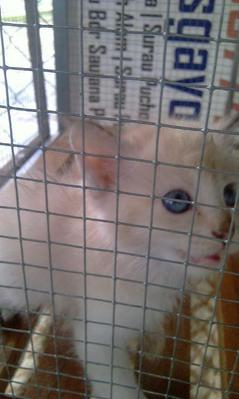

**Соседний интервал для класса 3: 000fb9572, y=3, prediction=2**

This puppy rescued from DBKL pound last wednesday, and been sent to vet for check out. Pls give this lovely puppy a loving home if you can.


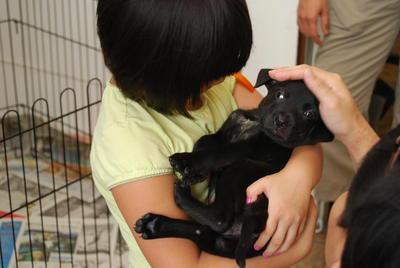

**Слишком оптимистичный прогноз: 01186c9fc, y=4, prediction=2**

Two playful active adorable kitties, in good health condition. One has a bit shortened tail.


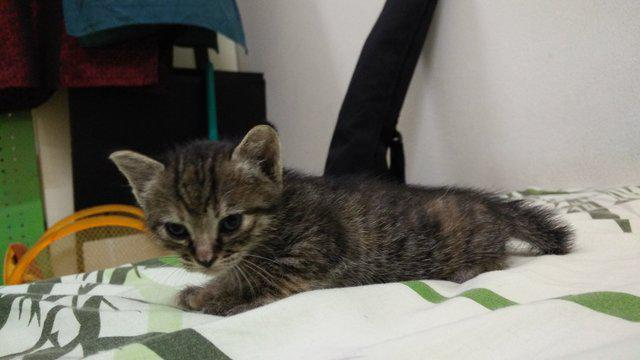

**Слишком пессимистичный прогноз: 01e78230b, y=1, prediction=4**

would anyone please adopt this kitty? i found it so i took care of him for a while . but my mom doesnt like me keeping him .. please adopt him or else i will have to throw him away


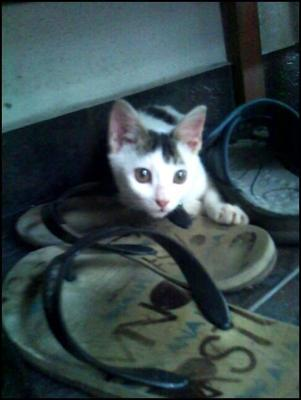

In [ ]:
hw3_frequency, hw3_cases = error_examples(hw3_analysis)
hw3_frequency.to_csv(HW3_DIR / 'error_patterns.csv', index=False)
hw3_cases.to_csv(HW3_DIR / 'error_examples.csv', index=False)
hw3_photos = export_first_photos(HW3_DATA_SOURCE, hw3_cases.PetID, HW3_DIR / 'case_photos')
display(hw3_frequency)
display(hw3_cases[['pattern', 'PetID', 'fold', 'y_true', 'prediction', 'Age', 'Quantity', 'Fee', 'PhotoAmt']])

# Наблюдения по выбранным карточкам, возможные причины отделены от фактов
for case in hw3_cases.itertuples(index=False):
    display(Markdown(f'**{case.pattern_description}: {case.PetID}, y={case.y_true}, prediction={case.prediction}**'))
    print(str(case.Description))
    if case.PetID in hw3_photos:
        display(Image(filename=str(hw3_photos[case.PetID]), width=450))
    else:
        print('Первое фото отсутствует в переданном источнике данных.')

Первый кейс. Котик. В описании много сведений об уходе и поиске хозяев, но по ним нельзя установить пристройство именно в день публикации. Гипотеза: доступных признаков недостаточно для отделения этого редкого случая от пристройства за 1–7 дней.

Второй кейс. Щенок. В тексте говорится о спасении из DBKL pound и визите к ветеринару. Фактическая ошибка — прогноз 8–30 дней вместо 31–90. Гипотеза: карточка не содержит явного сигнала, который отделяет эти соседние интервалы.

Третий кейс. В объявлении два котенка, а на первом фото виден один. Текст также говорит о двух животных. Метка относится к пристройству всей группы, Quantity=2 модель уже получает, но метаданные одного фото не описывают обоих животных. Гипотеза: групповой характер объявления и неполное визуальное описание связаны со слишком оптимистичным прогнозом. В таких случаях нужно смотреть сразу на все фотки.

Четвертый кейс. Котик. В описании автор срочно ищет хозяина: держать найденного котенка дома не разрешают. Модель предсказывает долгий срок, хотя животное пристроено за 1–7 дней. Гипотеза: срочность поиска хозяина несет дополнительный сигнал, выбранный CatBoost не использует Description.

In [4]:
HW3_CASE_NOTES = {
    '015da9e87': 'Первый кейс. Котик. В описании много сведений об уходе и поиске хозяев, но по ним нельзя установить пристройство именно в день публикации. Гипотеза: доступных признаков недостаточно для отделения этого редкого случая от пристройства за 1–7 дней.',
    '000fb9572': 'Второй кейс. Щенок. В тексте говорится о спасении из DBKL pound и визите к ветеринару. Фактическая ошибка — прогноз 8–30 дней вместо 31–90. Гипотеза: карточка не содержит явного сигнала, который отделяет эти соседние интервалы.',
    '01186c9fc': 'Третий кейс. В объявлении два котенка, а на первом фото виден один. Текст также говорит о двух животных. Метка относится к пристройству всей группы, Quantity=2 модель уже получает, но метаданные одного фото не описывают обоих животных. Гипотеза: групповой характер объявления и неполное визуальное описание связаны со слишком оптимистичным прогнозом. В таких случаях нужно смотреть сразу на все фотки.',
    '01e78230b': 'Четвертый кейс. Котик. В описании автор срочно ищет хозяина: держать найденного котенка дома не разрешают. Модель предсказывает долгий срок, хотя животное пристроено за 1–7 дней. Гипотеза: срочность поиска хозяина несет дополнительный сигнал, выбранный CatBoost не использует Description.',
}
save_json(HW3_CASE_NOTES, HW3_DIR / 'case_notes.json')

### Качество по срезам

Срезы: вид животного, возраст, одно/несколько животных, наличие фото. Для каждой группы сохраняется размер, число авторов, QWK, MAE, доля тяжелых ошибок и распределение target.
Возрастные границы те же, что в описательном разборе ДЗ1.
Для отдельных классов используем precision/recall/F1: QWK внутри одного истинного класса неинформативна.
Малые группы и различия распределения target учитываются.

,slice,group,n,rescuer_groups,qwk,mae,severe_error_rate
0,species,Кошки,6861,2947,0.322980,1.005247,0.276053
1,species,Собаки,8132,2944,0.335287,0.916995,0.250369
2,age,0–2 месяца,5986,2246,0.232937,0.921316,0.222686
3,age,3–11 месяцев,5258,2527,0.278463,0.993914,0.287181
4,age,12+ месяцев,3749,2257,0.322378,0.963724,0.289944
5,quantity,Несколько животных,3428,2123,0.298222,0.976954,0.278296
6,quantity,Одно животное,11565,4305,0.346643,0.951578,0.257328
7,photos,Есть фото,14652,5385,0.336443,0.958504,0.261603
8,photos,Нет фото,341,307,0.045756,0.909091,0.284457


,class,n,precision,recall,f1
0,0,410,0.000000,0.000000,0.000000
1,1,3090,0.339183,0.306472,0.321999
2,2,4037,0.334448,0.421105,0.372807
3,3,3259,0.368332,0.133477,0.195946
4,4,4197,0.473214,0.669288,0.554426


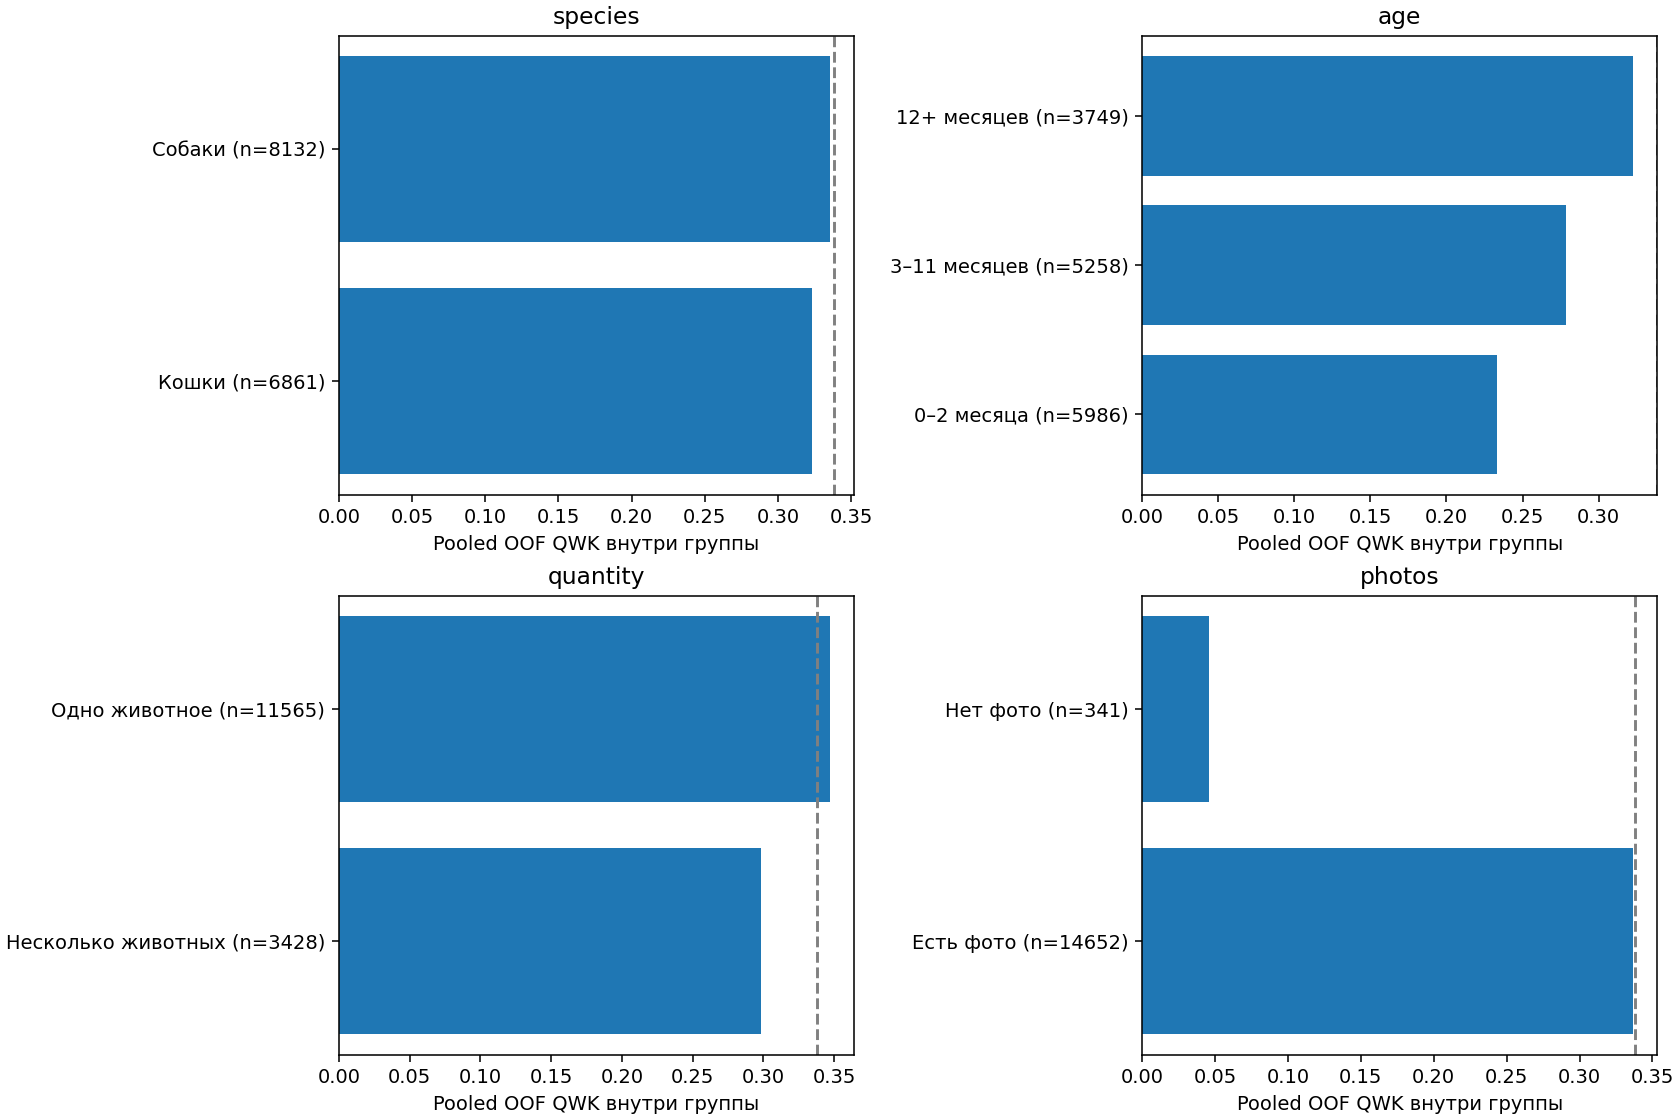

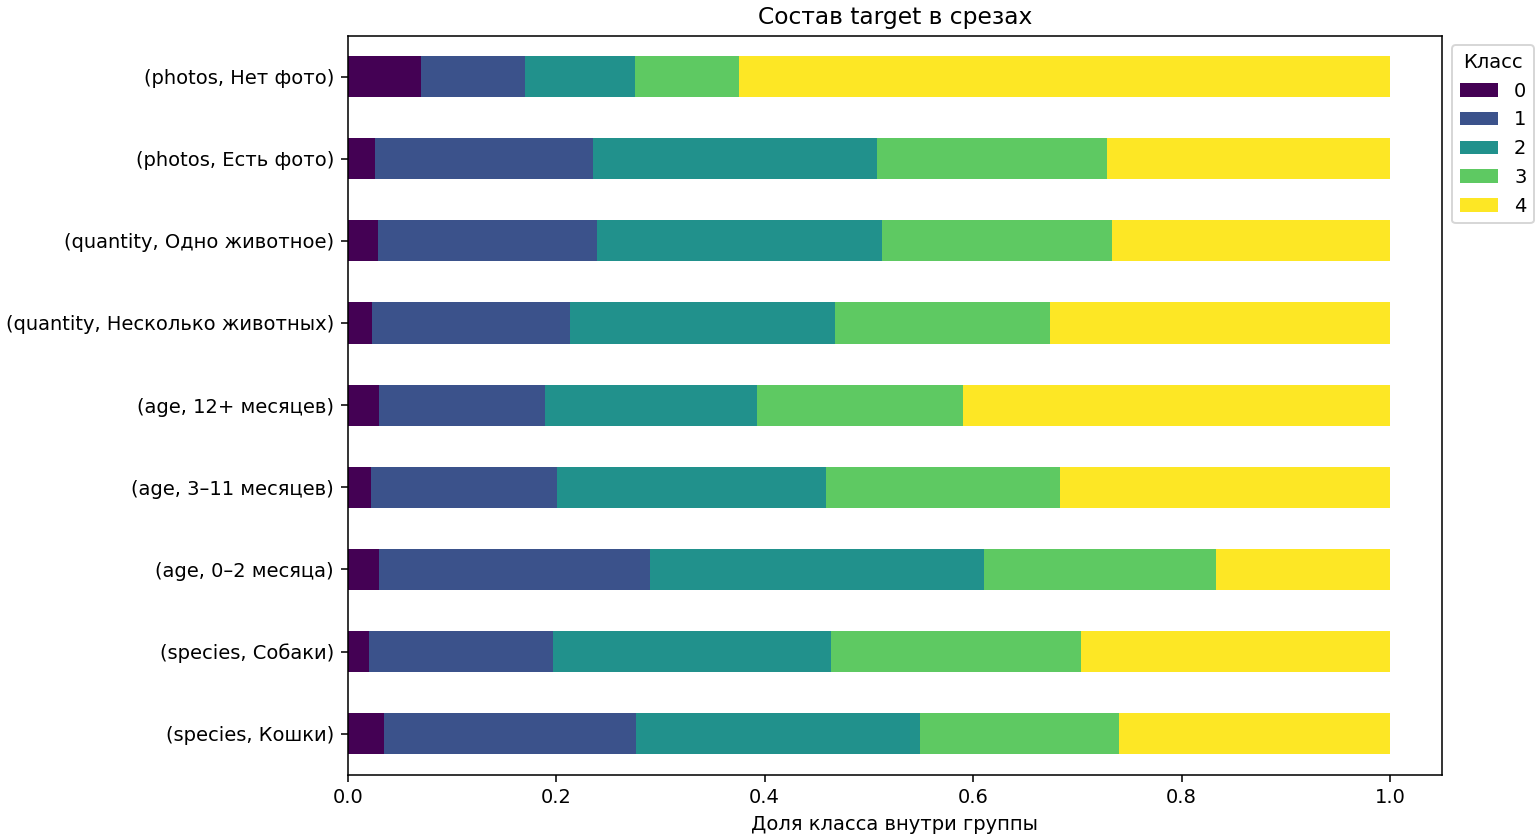

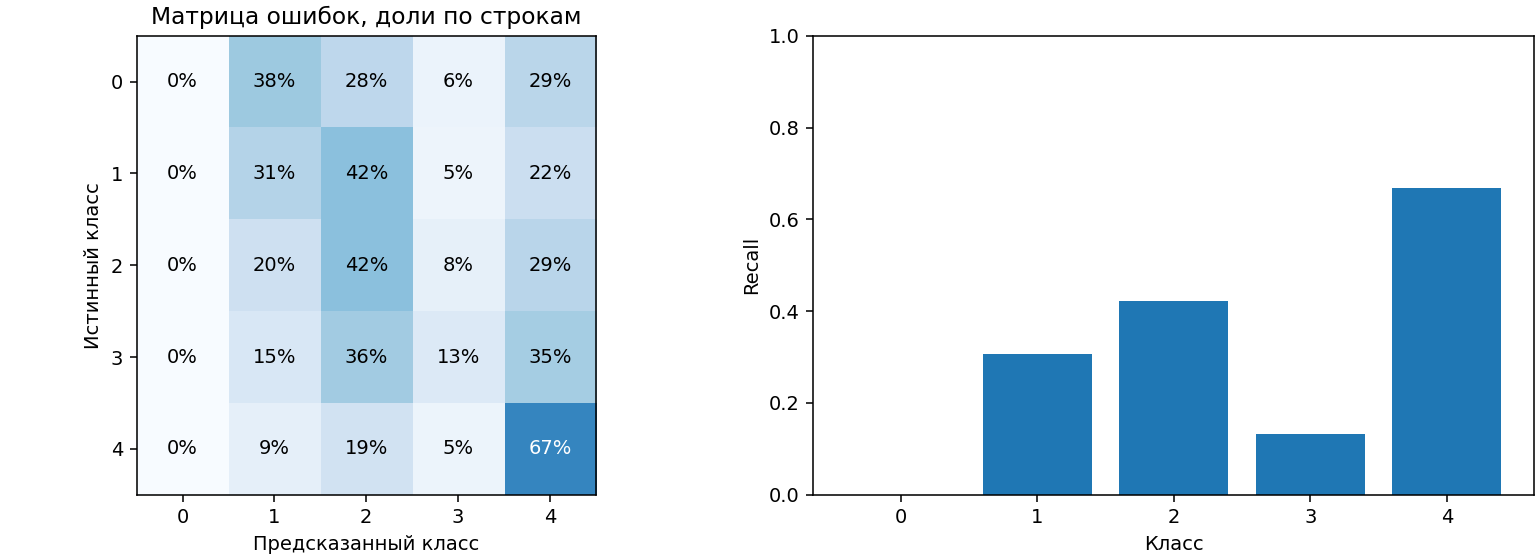

In [5]:
hw3_slices = slice_metrics(hw3_analysis)
hw3_classes = diagnostic_class_metrics(hw3_analysis)
hw3_slices.to_csv(HW3_DIR / 'slices.csv', index=False)
hw3_classes.to_csv(HW3_DIR / 'class_metrics.csv', index=False)
display(hw3_slices[['slice', 'group', 'n', 'rescuer_groups', 'qwk', 'mae', 'severe_error_rate']])
display(hw3_classes)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
for ax, dimension in zip(axes.flat, ['species', 'age', 'quantity', 'photos']):
    group = hw3_slices.loc[hw3_slices['slice'].eq(dimension)]
    labels = [f'{r.group} (n={r.n})' for r in group.itertuples(index=False)]
    ax.barh(labels, group.qwk)
    ax.axvline(hw3_reference_summary.oof_qwk, color='grey', linestyle='--', label='Общий pooled OOF QWK')
    ax.set(title=dimension, xlabel='Pooled OOF QWK внутри группы')
fig.savefig(HW3_DIR / 'slices.png', dpi=140)
plt.close(fig)
display(Image(filename=str(HW3_DIR / 'slices.png')))

fig, ax = plt.subplots(figsize=(11, 6), layout='constrained')
target_shares = hw3_slices.set_index(['slice', 'group'])[[f'class_{c}_share' for c in CLASSES]]
target_shares.columns = [str(c) for c in CLASSES]
target_shares.plot.barh(stacked=True, ax=ax, colormap='viridis')
ax.set(xlabel='Доля класса внутри группы', ylabel='', title='Состав target в срезах')
ax.legend(title='Класс', bbox_to_anchor=(1, 1))
fig.savefig(HW3_DIR / 'slice_target_distribution.png', dpi=140)
plt.close(fig)
display(Image(filename=str(HW3_DIR / 'slice_target_distribution.png')))

matrix = confusion_matrix(hw3_analysis.y_true, hw3_analysis.prediction, labels=CLASSES)
normalized = matrix / matrix.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
axes[0].imshow(normalized, cmap='Blues', vmin=0, vmax=1)
for (i, j), value in np.ndenumerate(normalized):
    axes[0].text(j, i, f'{value:.0%}', ha='center', va='center', color='white' if value > 0.5 else 'black')
axes[0].set(xticks=CLASSES, yticks=CLASSES, xlabel='Предсказанный класс', ylabel='Истинный класс', title='Матрица ошибок, доли по строкам')
axes[1].bar(CLASSES, hw3_classes.recall)
axes[1].set(xticks=CLASSES, xlabel='Класс', ylabel='Recall', ylim=(0, 1))
fig.savefig(HW3_DIR / 'classes.png', dpi=140)
plt.close(fig)
display(Image(filename=str(HW3_DIR / 'classes.png')))

### Что видно по исходным OOF

Класс 0 не распознается: recall равен нулю. Для класса 3 около 71% объявлений попадают в соседние интервалы.

У групповых объявлений QWK ниже, чем у одиночных, и доля тяжелых ошибок выше. Это согласуется со сложностью прогноза для пристройства всей группы.

На 341 карточке без фото QWK очень низкий, размер и состав этой группы отличаются от остальных, поэтому переносить наблюдение на эффект добавления фотографии нельзя.

У молодых животных QWK ниже, но MAE и доля тяжелых ошибок не обязательно выше: разные метрики отражают разные стороны ошибок.

### Данные для переобучения

Для robustness-проверок используем те же десять признаков фото, что в выбранном эксперименте ДЗ2.
При наличии берем сохраненную таблицу признаков. Если ее нет, рассчитываем признаки из исходных JSON.

In [6]:
hw3_photo_path = HW3_REFERENCE.parent / 'photo_features/train.csv'
if hw3_photo_path.is_file():
    hw3_photo_train = pd.read_csv(hw3_photo_path)
else:
    hw3_photo_train = load_photo_features(HW3_DATA_SOURCE, hw3_train.PetID, split='train')
if not hw3_photo_train.PetID.is_unique or set(hw3_photo_train.PetID) != set(hw3_train.PetID):
    raise ValueError('Признаки фото не покрывают текущий train по PetID')
hw3_train_with_photo = hw3_train.join(hw3_photo_train.set_index('PetID')[PHOTO_FEATURES],
                                    on='PetID', validate='one_to_one')
print('Данные для robustness:', hw3_train_with_photo.shape)

Данные для robustness: (14993, 34)


### Устойчивость 1: другое групповое разбиение

Меняем только `split_seed`: 42, 17, 2026. Seed модели остается 42, алгоритм разбиения — StratifiedGroupKFold с пятью фолдами по RescuerID.
Для seed=42 используем готовый результат ДЗ2, для двух других seed обучаем еще десять моделей с теми же параметрами.
Повторный bootstrap для этих запусков выключен: он не влияет на обучение и не нужен для сравнения трех разбиений.
Лучший seed не выбираем, смотрим чувствительность уже выбранной конфигурации. Три разбиения дают ограниченную оценку устойчивости.

Групповое разбиение seed=17, model seed=42
catboost_classifier fold=0 QWK=0.3305390363930458
catboost_classifier fold=1 QWK=0.3490067797741666
catboost_classifier fold=2 QWK=0.3435700600446837
catboost_classifier fold=3 QWK=0.3373147534864751
catboost_classifier fold=4 QWK=0.2990851389421797
Групповое разбиение seed=2026, model seed=42
catboost_classifier fold=0 QWK=0.3221608623510652
catboost_classifier fold=1 QWK=0.33959388365193355
catboost_classifier fold=2 QWK=0.326638498676019
catboost_classifier fold=3 QWK=0.3299513854081927
catboost_classifier fold=4 QWK=0.3524057646647296


,split_seed,model_seed,qwk_mean,qwk_std,oof_macro_f1,oof_mae,oof_severe_error_rate
0,42,42,0.338184,0.021835,0.289036,0.957380,0.262122
1,17,42,0.331903,0.019601,0.284279,0.959581,0.262122
2,2026,42,0.334150,0.012049,0.286752,0.961315,0.264790


Среднее mean fold QWK по разбиениям: 0.3347455864027386
Std между разбиениями: 0.003182254307271181


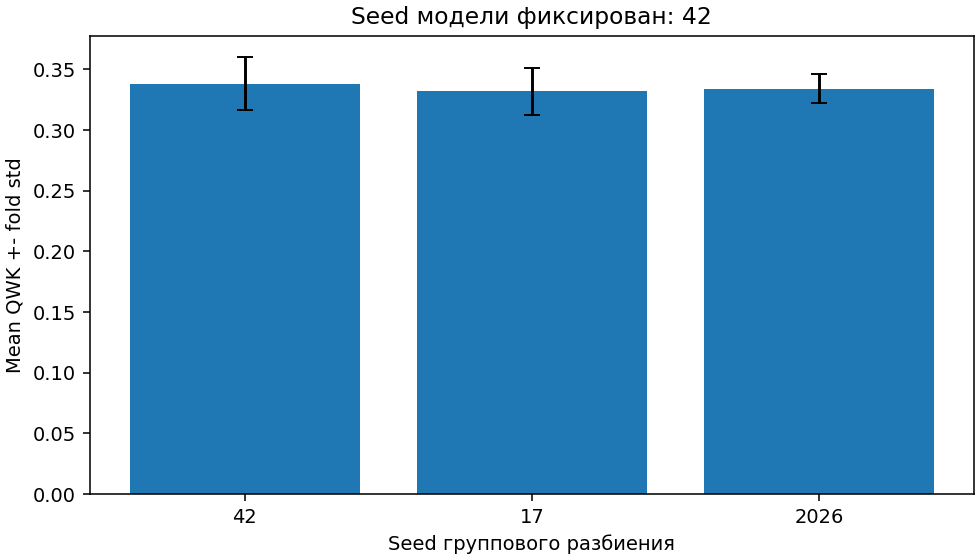

In [7]:
if RUN_SPLIT_CHECK:
    hw3_split_rows = []
    for split_seed in HW3_SETTINGS['split_seeds']:
        if split_seed == 42:
            row = hw3_reference_summary.to_dict()
            row['source'] = 'Сохраненный эксперимент ДЗ2'
        else:
            settings = deepcopy(HW3_MODEL_CONFIG)
            settings['split_seed'] = split_seed
            settings['bootstrap_repeats'] = 0
            destination = HW3_DIR / 'splits' / f'seed_{split_seed}'
            print(f'Групповое разбиение seed={split_seed}, model seed={settings["seed"]}', flush=True)
            result = run_cv(hw3_train_with_photo, settings, destination)
            row = result.iloc[0].to_dict()
            row['source'] = str(destination)
        row.update(split_seed=split_seed, model_seed=HW3_MODEL_CONFIG['seed'])
        hw3_split_rows.append(row)
        pd.DataFrame(hw3_split_rows).to_csv(HW3_DIR / 'split_robustness.csv', index=False)
    hw3_split_results = pd.DataFrame(hw3_split_rows)
    display(hw3_split_results[['split_seed', 'model_seed', 'qwk_mean', 'qwk_std', 'oof_macro_f1', 'oof_mae', 'oof_severe_error_rate']])
    print('Среднее mean fold QWK по разбиениям:', hw3_split_results.qwk_mean.mean())
    print('Std между разбиениями:', hw3_split_results.qwk_mean.std(ddof=1))
    fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
    ax.bar(hw3_split_results.split_seed.astype(str), hw3_split_results.qwk_mean,
           yerr=hw3_split_results.qwk_std, capsize=4)
    ax.set(xlabel='Seed группового разбиения', ylabel='Mean QWK +- fold std', title='Seed модели фиксирован: 42')
    fig.savefig(HW3_DIR / 'split_robustness.png', dpi=140)
    plt.close(fig)
    display(Image(filename=str(HW3_DIR / 'split_robustness.png')))
else:
    print('Проверка других разбиений отключена.')

### Устойчивость 2: неточность возраста

На исходных фолдах seed=42 обучаем пять моделей на чистом train. Затем меняем только Age на validation:
`max(0, round(Age + sigma * N(0, 1)))`, sigma = 0, 1, 3 месяца.
Для ненулевого шума используем три фиксированных seed. Для одного seed базовый случайный вектор одинаков на всех уровнях sigma.
Модели не переобучаются под шум, остальные признаки, validation-карточки и их метки остаются прежними.

Age noise: fold=0, обучение 72.0 с, все уровни шума проверены
Age noise: fold=1, обучение 84.3 с, все уровни шума проверены
Age noise: fold=2, обучение 83.7 с, все уровни шума проверены
Age noise: fold=3, обучение 92.8 с, все уровни шума проверены
Age noise: fold=4, обучение 94.5 с, все уровни шума проверены


,sigma,repeats,qwk_mean,qwk_std_between_noise_repeats,delta_mean_qwk,oof_qwk,oof_mae,oof_recall_class_0,oof_severe_error_rate,changed_age_rate,prediction_flip_rate
0,0,1,0.338184,0.000000,0.000000,0.338022,0.957380,0.000000,0.262122,0.000000,0.000000
1,1,3,0.321953,0.003118,-0.016231,0.321404,0.977256,0.000000,0.271771,0.608217,0.082994
2,3,3,0.277193,0.005208,-0.060990,0.276461,1.034038,0.000813,0.298739,0.862291,0.182752


Повторный clean QWK: 0.3381835265297175 QWK ДЗ2: 0.3381835265297175
Delta шума в таблице рассчитана относительно повторного clean, не относительно нового разбиения.


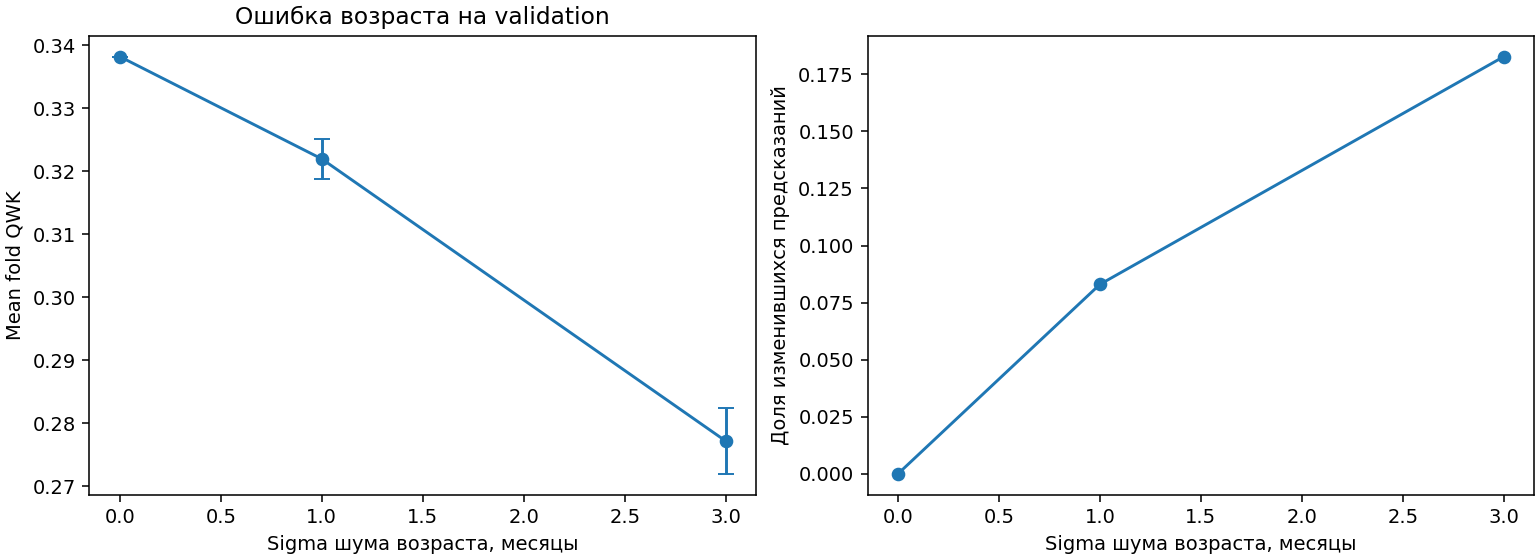

Усы на графике QWK — std между повторениями.


In [9]:
if RUN_AGE_NOISE_CHECK:
    hw3_noise_runs, hw3_noise_summary = run_age_noise(
        hw3_train_with_photo, HW3_MODEL_CONFIG, hw3_reference_folds, HW3_DIR / 'age_noise',
        sigmas=HW3_SETTINGS['age_noise']['sigmas'], seeds=HW3_SETTINGS['age_noise']['seeds'])
    display(hw3_noise_summary)
    hw3_clean_qwk = float(hw3_noise_summary.loc[hw3_noise_summary.sigma.eq(0), 'qwk_mean'].iloc[0])
    save_json({'reference_mean_qwk': float(hw3_reference_summary.qwk_mean),
               'repeated_clean_mean_qwk': hw3_clean_qwk,
               'delta': hw3_clean_qwk - float(hw3_reference_summary.qwk_mean)}, HW3_DIR / 'age_noise/reproduction.json')
    print('Повторный clean QWK:', hw3_clean_qwk, 'QWK ДЗ2:', hw3_reference_summary.qwk_mean)
    print('Delta шума в таблице рассчитана относительно повторного clean, не относительно нового разбиения.')
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
    axes[0].errorbar(hw3_noise_summary.sigma, hw3_noise_summary.qwk_mean,
                     yerr=hw3_noise_summary.qwk_std_between_noise_repeats, marker='o', capsize=4)
    axes[0].set(xlabel='Sigma шума возраста, месяцы', ylabel='Mean fold QWK', title='Ошибка возраста на validation')
    axes[1].plot(hw3_noise_summary.sigma, hw3_noise_summary.prediction_flip_rate, marker='o')
    axes[1].set(xlabel='Sigma шума возраста, месяцы', ylabel='Доля изменившихся предсказаний')
    fig.savefig(HW3_DIR / 'age_noise.png', dpi=140)
    plt.close(fig)
    display(Image(filename=str(HW3_DIR / 'age_noise.png')))
    print('Усы на графике QWK — std между повторениями.')
else:
    print('Проверка шума возраста отключена.')

### Ограничения и доверие к модели

- Скорость пристройства в день публикации модель не распознает. Использовать ее для поиска таких случаев нельзя.
- Для групповых объявлений и карточек без фото качество ниже.
- Предсказывается категория времени. Точное число дней и вероятность успешного пристройства модель не оценивает.
- Это данные PetFinder с представленными регионами и процессом публикации. Перенос на другую площадку, страну или период требует отдельной проверки.
- Возраст и ветеринарные статусы указаны авторами. Нет истории карточек: неизвестно, какие поля могли обновиться уже после публикации или пристройства.
- Группировка по RescuerID исключает одного автора по обе стороны train/validation. Похожие карточки и изображения разных авторов этим не исключаются. Совпадение текста само по себе не доказывает утечку, Description выбранная модель не использует.
- Частоты, OOF и разбор отдельных карточек не доказывают причины ошибок. Сомнительную метку нельзя объявлять неправильной только потому, что прогноз с ней расходится.
- Прогноз может быть вспомогательным сигналом для ручного просмотра объявлений. Автоматически лишать карточки продвижения на его основе нельзя обосновать проведенной оценкой.

In [10]:
print('Результаты ДЗ3:', HW3_DIR)
print('Ошибки: error_patterns.csv, error_examples.csv, case_notes.json и case_photos/')
print('Срезы: slices.csv, class_metrics.csv и графики slices.png, slice_target_distribution.png, classes.png')
if RUN_SPLIT_CHECK:
    print('Разбиения: split_robustness.csv, split_robustness.png и папка splits/')
if RUN_AGE_NOISE_CHECK:
    print('Шум: age_noise/summary.csv, runs.csv, fold_metrics.csv, OOF и график age_noise.png')

Результаты ДЗ3: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/outputs/hw3_20261126_135325_244431
Ошибки: error_patterns.csv, error_examples.csv, case_notes.json и case_photos/
Срезы: slices.csv, class_metrics.csv и графики slices.png, slice_target_distribution.png, classes.png
Разбиения: split_robustness.csv, split_robustness.png и папка splits/
Шум: age_noise/summary.csv, runs.csv, fold_metrics.csv, OOF и график age_noise.png
